# Tratamiento de outliers y transformaciones (Issue 6)

**Objetivo:** definir un tratamiento para cada variable numérica que deja la cadena (Issues 2 → 3 → 4 → 5), de modo que queden listas para la regresión logística y para el PCA del Issue 7. El PCA es sensible a la escala y a los valores extremos.

Este notebook continúa `issue5.ipynb`. Recibe los datos ya filtrados por los issues anteriores:

1. **Redundancia (Issue 3):** columnas colineales o casi constantes eliminadas.
2. **Nulos (Issue 5):** cada columna imputada con la mediana o la moda de entrenamiento, más un indicador `<columna>_nulo` cuando el faltante es informativo.

Sobre esos datos se recorren cinco pasos:

1. Revisar valores extremos, valores imposibles y asimetría, **solo con los valores observados**: los que imputó el Issue 5 se excluyen usando sus indicadores.
2. Definir por reglas qué variables reciben winsorización y cuáles `log1p`.
3. Comparar en validación cuatro tratamientos (sin tratar, `log1p`, winsorización, winsorización + `log1p`), cada uno con `RobustScaler` y con `StandardScaler`.
4. Elegir el escalado final.
5. Dejar las particiones tratadas para el PCA del Issue 7.

**Reglas:**

- Percentiles, elección de columnas y escalas se ajustan solo con `X_train`.
- `X_val` se usa solo para comparar.
- `X_test` no interviene en ninguna decisión; al final solo recibe el pipeline ya ajustado.

El código está en [`src/features.py`](../src/features.py).

> **Antes de ejecutar:** la primera celda carga el checkpoint de [`issue5.ipynb`](issue5.ipynb) (`data/checkpoints/issue5/`). Si no existe, ejecuta ese notebook, que encadena los issues 2 a 5.
>
> **Para el Issue 7:** al final (sección 8), las columnas numéricas de `X_train`, `X_val` y `X_test` quedan tratadas con el pipeline elegido; las categóricas pasan sin cambios. Se guardan en `data/checkpoints/issue6/`.

In [1]:
# Carga el checkpoint de issue5 (data/checkpoints/issue5/) en lugar de ejecutar toda la cadena.
# Si no existe, se ejecuta issue5.ipynb, que lo genera al terminar.
import sys
sys.path.append('..')
from src.checkpoints import cargar_checkpoint, existe_checkpoint

if existe_checkpoint('issue5'):
    globals().update(cargar_checkpoint('issue5'))
else:
    %run issue5.ipynb

Checkpoint issue5 cargado: X_train (862757, 117), X_val (215690, 117), X_test (269612, 117), y_train (862757,), y_val (215690,), y_test (269612,)


In [2]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

from src.data import SEED
from src.features import (
    SUFIJO_INDICADOR, PreprocesadorNumerico, columnas_duplicadas, definir_tratamientos,
    enmascarar_imputados, resumen_asimetria,
)

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)

DIR_FIGURAS = Path.cwd().parent / 'reports' / 'figures'
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
})

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=150, bbox_inches='tight')
    print(f'Figura guardada en reports/figures/{nombre}')

## 1. Datos de la cadena

Se toman las columnas numéricas de `X_train` y `X_val` que deja `issue5.ipynb`. Las categóricas no se tratan aquí: su codificación no es parte de este issue.

In [3]:
X_ent = X_train.select_dtypes('number')
y_ent = y_train
X_val_num = X_val[X_ent.columns]   # sin pisar X_val de la cadena

indicadores = [c for c in X_ent.columns if c.endswith(SUFIJO_INDICADOR)]
originales = [c for c in X_ent.columns if c not in indicadores]
print(f'Entrenamiento: {X_ent.shape}; validación: {X_val_num.shape}')
print(f'Numéricas: {len(originales)} variables originales + {len(indicadores)} indicadores de nulo del Issue 5')
print(f'Categóricas que pasan sin cambios: {list(X_train.select_dtypes(exclude="number").columns)}')
print(f'NaN que llegan del Issue 5: {X_ent.isna().sum().sum()}')

Entrenamiento: (862757, 109); validación: (215690, 109)
Numéricas: 61 variables originales + 48 indicadores de nulo del Issue 5
Categóricas que pasan sin cambios: ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'earliest_cr_line', 'application_type']
NaN que llegan del Issue 5: 0


### Valores imputados por el Issue 5

El Issue 5 imputó con la mediana de entrenamiento. En columnas con mucho faltante, esa mediana repetida concentra la distribución en un solo valor y distorsiona justo lo que mide este issue: percentiles, asimetría e IQR.

Por eso `enmascarar_imputados` vuelve a marcar como NaN las filas imputadas, usando el indicador `<columna>_nulo`. Todas las estadísticas de este notebook (resumen, reglas y percentiles de la winsorización) se calculan sobre esos **valores observados**. Las columnas que el Issue 5 imputó sin indicador tenían menos de 1,000 nulos, así que su efecto es despreciable.

In [4]:
X_obs = enmascarar_imputados(X_ent)
pct_imputado = (X_obs.isna().mean() * 100).loc[originales]
print(f'Columnas con valores imputados que se excluyen del análisis: {(pct_imputado > 0).sum()}')

comparacion_mascara = []
for col in ['max_bal_bc', 'open_rv_24m', 'mths_since_last_record', 'avg_cur_bal']:
    imputada, observada = X_ent[col], X_obs[col].dropna()
    for nombre, v in (('con imputados', imputada), ('solo observados', observada)):
        q = v.quantile([0.01, 0.25, 0.75, 0.99])
        comparacion_mascara.append({'columna': col, 'datos': nombre, '% imputado': pct_imputado[col],
                                    'p1': q[0.01], 'Q1': q[0.25], 'Q3': q[0.75], 'p99': q[0.99],
                                    'asimetría': v.skew()})
pd.DataFrame(comparacion_mascara).set_index(['columna', 'datos']).round(2)

Columnas con valores imputados que se excluyen del análisis: 47


% imputado     p1      Q1       Q3       p99  asimetría
columna                datos                                                                   
max_bal_bc             con imputados         60.10    0.0  4207.0   4207.0  19404.44      18.92
                       solo observados       60.10    0.0  2185.0   7214.0  24374.42      12.16
open_rv_24m            con imputados         60.10    0.0     2.0      2.0     10.00       3.64
                       solo observados       60.10    0.0     1.0      4.0     12.00       1.92
mths_since_last_record con imputados         82.99   25.0    71.0     71.0    112.00      -0.80
                       solo observados       82.99    5.0    53.0     90.0    118.00      -0.28
avg_cur_bal            con imputados          5.22  477.0  3248.0  17899.0  72298.88       4.13
                       solo observados        5.22  462.0  3105.0  18722.0  73411.14       4.01

Con la mediana imputada, el IQR de las columnas del bloque de 2016 se encoge o se anula: más de la mitad de los valores son idénticos. Los percentiles se desplazan y la asimetría cambia. Por eso se usan los valores observados.

La imputación del Issue 5 no se modifica: el pipeline transforma los datos imputados tal como llegan. Como la mediana no se mueve al recortar por percentiles ni al aplicar `log1p` (ambas son transformaciones crecientes), transformar los datos imputados da el mismo resultado que imputar después de transformar.

### Indicadores de nulo duplicados

Varios bloques de columnas comparten exactamente el mismo patrón de nulos: las 13 del buró que faltan juntas, o el bloque que se registra desde 2016. Sus indicadores son, por lo tanto, copias exactas.

In [5]:
grupos = columnas_duplicadas(X_ent[indicadores])
distintos = len(indicadores) - sum(len(g) - 1 for g in grupos)
print(f'{len(indicadores)} indicadores, {distintos} distintos; {len(grupos)} grupos de copias exactas:')
for grupo in grupos:
    print(f'  {len(grupo):>2} idénticos: {", ".join(grupo)}')

48 indicadores, 24 distintos; 5 grupos de copias exactas:
   2 idénticos: mo_sin_rcnt_rev_tl_op_nulo, mo_sin_old_rev_tl_op_nulo
  13 idénticos: total_rev_hi_lim_nulo, tot_coll_amt_nulo, total_il_high_credit_limit_nulo, tot_hi_cred_lim_nulo, num_tl_op_past_12m_nulo, num_bc_tl_nulo, num_op_rev_tl_nulo, num_il_tl_nulo, mo_sin_rcnt_tl_nulo, num_tl_90g_dpd_24m_nulo, num_actv_rev_tl_nulo, num_actv_bc_tl_nulo, num_accts_ever_120_pd_nulo
   4 idénticos: total_bal_ex_mort_nulo, total_bc_limit_nulo, mort_acc_nulo, acc_open_past_24mths_nulo
   3 idénticos: open_acc_6m_nulo, total_cu_tl_nulo, inq_last_12m_nulo
   7 idénticos: open_act_il_nulo, open_il_12m_nulo, inq_fi_nulo, open_rv_12m_nulo, open_rv_24m_nulo, max_bal_bc_nulo, open_il_24m_nulo


Este issue no cambia la salida del Issue 5: los indicadores duplicados no afectan a la regresión logística, que reparte el peso entre las copias. Sí importan para el PCA del Issue 7: un bloque de 13 columnas idénticas aporta 13 veces la misma varianza y arrastra a los primeros componentes. Se recomienda que el Issue 5 (o el 7, antes de ajustar el PCA) deje un solo indicador por grupo.

## 2. Valores extremos y valores imposibles

`resumen_asimetria` calcula, con los valores observados de entrenamiento:

- Percentiles 1 y 99.
- `max_sobre_p99`: cuántas veces el máximo supera al percentil 99.
- El porcentaje de valores fuera de [Q1 − 3·IQR, Q3 + 3·IQR].
- Tres asimetrías de Fisher: cruda, recortada a los percentiles 1 y 99, y recortada después de `log1p`.

In [6]:
resumen = resumen_asimetria(X_obs)
resumen.loc[originales].sort_values('max_sobre_p99', ascending=False).head(15).round(2)

,n_unicos,min,p1,mediana,p99,max,max_sobre_p99,pct_fuera_iqr,asim_cruda,asim_recortada,asim_log_recortada
columna,,,,,,,,,,,
tot_coll_amt,10597,0.0,0.00,0.00,4923.00,5252395.0,1066.91,15.35,721.64,5.86,2.14
total_rev_hi_lim,19522,0.0,2800.00,24000.00,157700.00,9999999.0,63.41,2.05,33.13,2.13,-0.16
pub_rec,31,0.0,0.00,0.00,2.00,86.0,43.00,16.91,12.53,2.32,1.98
tax_liens,31,0.0,0.00,0.00,2.00,85.0,42.50,3.19,35.50,6.38,5.80
annual_inc,47492,0.0,18000.00,65000.00,252000.00,9550000.0,37.90,1.64,42.98,1.72,0.09
max_bal_bc,25038,0.0,0.00,4207.00,24374.42,776843.0,31.87,1.50,12.16,1.68,-3.11
revol_bal,73132,0.0,167.56,11129.00,95671.44,2904836.0,30.36,2.31,12.12,2.58,-0.97
dti,6375,-1.0,1.76,17.62,38.45,999.0,25.98,0.12,26.58,0.24,NaN
num_tl_90g_dpd_24m,28,0.0,0.00,0.00,2.00,39.0,19.50,5.73,13.36,4.66,4.17


Varias colas no son ingresos o saldos extremos legítimos, sino valores imposibles o centinelas:

In [7]:
revisiones = {
    'dti = 999 (centinela)': (X_obs['dti'] == 999).sum(),
    'dti > 100': (X_obs['dti'] > 100).sum(),
    'dti < 0': (X_obs['dti'] < 0).sum(),
    'annual_inc = 0': (X_obs['annual_inc'] == 0).sum(),
    'annual_inc > 1 millón': (X_obs['annual_inc'] > 1e6).sum(),
    'revol_util > 100 %': (X_obs['revol_util'] > 100).sum(),
    'total_rev_hi_lim = 9,999,999': (X_obs['total_rev_hi_lim'] == 9_999_999).sum(),
    'tot_hi_cred_lim = 9,999,999': (X_obs['tot_hi_cred_lim'] == 9_999_999).sum(),
    'tot_coll_amt > 100,000': (X_obs['tot_coll_amt'] > 1e5).sum(),
}
pd.Series(revisiones, name='préstamos en entrenamiento').to_frame()

,préstamos en entrenamiento
dti = 999 (centinela),23
dti > 100,330
dti < 0,1
annual_inc = 0,229
annual_inc > 1 millón,189
revol_util > 100 %,3026
"total_rev_hi_lim = 9,999,999",1
"tot_hi_cred_lim = 9,999,999",8
"tot_coll_amt > 100,000",26


Interpretación de estos casos:

- **`dti`:** valores como 999 o mayores a 100 % son imposibles para la razón deuda/ingreso de una solicitud aprobada. Se deben a ingresos casi nulos o a un código de "sin dato".
- **`annual_inc`:** un ingreso de 0 o de varios millones en un préstamo de consumo de hasta 40,000 USD es improbable, y además es un dato autodeclarado.
- **`total_rev_hi_lim` y `tot_hi_cred_lim`:** 9,999,999 es un valor tope del buró.
- **`revol_util`:** puede superar el 100 % legítimamente (sobregiro), pero los valores de 300 % son extremos.

Eliminar estas filas cambiaría la población del Issue 2. Además, en producción también llegarían solicitudes con estos valores. Por eso **no se eliminan filas: se recortan** a percentiles aprendidos en entrenamiento.

## 3. Asimetría y reglas de tratamiento

La asimetría cruda engaña: `tot_coll_amt` la tiene altísima por un solo préstamo con 5 millones. Por eso la regla usa la asimetría **recortada** a los percentiles 1 y 99, que mide la forma de la distribución sin unos pocos extremos.

Reglas de `definir_tratamientos`:

1. **Variables binarias** (los indicadores `_nulo` del Issue 5): no se recortan ni se transforman, solo se escalan.
2. **Winsorización:** se aplica a todas las variables no binarias, con los percentiles 1 y 99 de entrenamiento. Limita centinelas y valores imposibles sin eliminar filas.
3. **`log1p`:** se aplica solo si se cumplen tres condiciones:
   - La variable no tiene negativos.
   - Su asimetría recortada supera 1.
   - El logaritmo la reduce al menos a la mitad en valor absoluto.

La tercera condición evita aplicar logaritmos donde no ayudan:

- Rangos estrechos como `fico_range_low` (615–845).
- Conteos con muchos ceros (`pub_rec`, `delinq_2yrs`, `tax_liens`), cuya asimetría viene de la masa en cero.
- Variables donde el logaritmo invierte la asimetría (`max_bal_bc`).

In [8]:
tratamientos = definir_tratamientos(resumen)
tabla_tratamientos = resumen[['min', 'mediana', 'p1', 'p99', 'max', 'asim_cruda', 'asim_recortada', 'asim_log_recortada']].join(tratamientos['tratamiento'])
print(tratamientos['tratamiento'].value_counts().to_string())
tabla_tratamientos.loc[originales].sort_values('asim_recortada', ascending=False).round(2)

tratamiento
sin transformación (binaria)    48
winsorización                   34
winsorización + log1p           27


,min,mediana,p1,p99,max,asim_cruda,asim_recortada,asim_log_recortada,tratamiento
columna,,,,,,,,,
collections_12_mths_ex_med,0.0,0.00,0.00,1.00,14.0,13.32,7.80,7.80,winsorización
tax_liens,0.0,0.00,0.00,2.00,85.0,35.50,6.38,5.80,winsorización
tot_coll_amt,0.0,0.00,0.00,4923.00,5252395.0,721.64,5.86,2.14,winsorización + log1p
num_tl_90g_dpd_24m,0.0,0.00,0.00,2.00,39.0,13.36,4.66,4.17,winsorización
num_accts_ever_120_pd,0.0,0.00,0.00,6.00,51.0,5.10,3.04,1.92,winsorización
delinq_2yrs,0.0,0.00,0.00,4.00,39.0,5.67,3.03,2.11,winsorización
mths_since_rcnt_il,0.0,12.00,1.00,129.00,488.0,3.51,2.81,0.27,winsorización + log1p
revol_bal,0.0,11129.00,167.56,95671.44,2904836.0,12.12,2.58,-0.97,winsorización + log1p
mo_sin_rcnt_rev_tl_op,0.0,8.00,0.00,84.00,438.0,3.47,2.53,0.10,winsorización + log1p


¿Cambia la decisión si las reglas se calculan con los datos imputados en lugar de los observados?

In [9]:
tratamientos_imputados = definir_tratamientos(resumen_asimetria(X_ent))
cambios = tratamientos[['tratamiento']].join(tratamientos_imputados['tratamiento'].rename('con datos imputados'))
cambios = cambios[cambios['tratamiento'] != cambios['con datos imputados']]
print(f'Columnas cuyo tratamiento cambiaría: {len(cambios)}')
cambios.join(pct_imputado.rename('% imputado').round(1))

Columnas cuyo tratamiento cambiaría: 5


,tratamiento,con datos imputados,% imputado
columna,,,
open_il_12m,winsorización + log1p,winsorización,60.1
total_cu_tl,winsorización + log1p,winsorización,60.1
mths_since_recent_inq,winsorización,winsorización + log1p,13.1
num_bc_tl,winsorización,winsorización + log1p,5.2
num_tl_op_past_12m,winsorización,winsorización + log1p,5.2


Figura guardada en reports/figures/outliers_asimetria.png


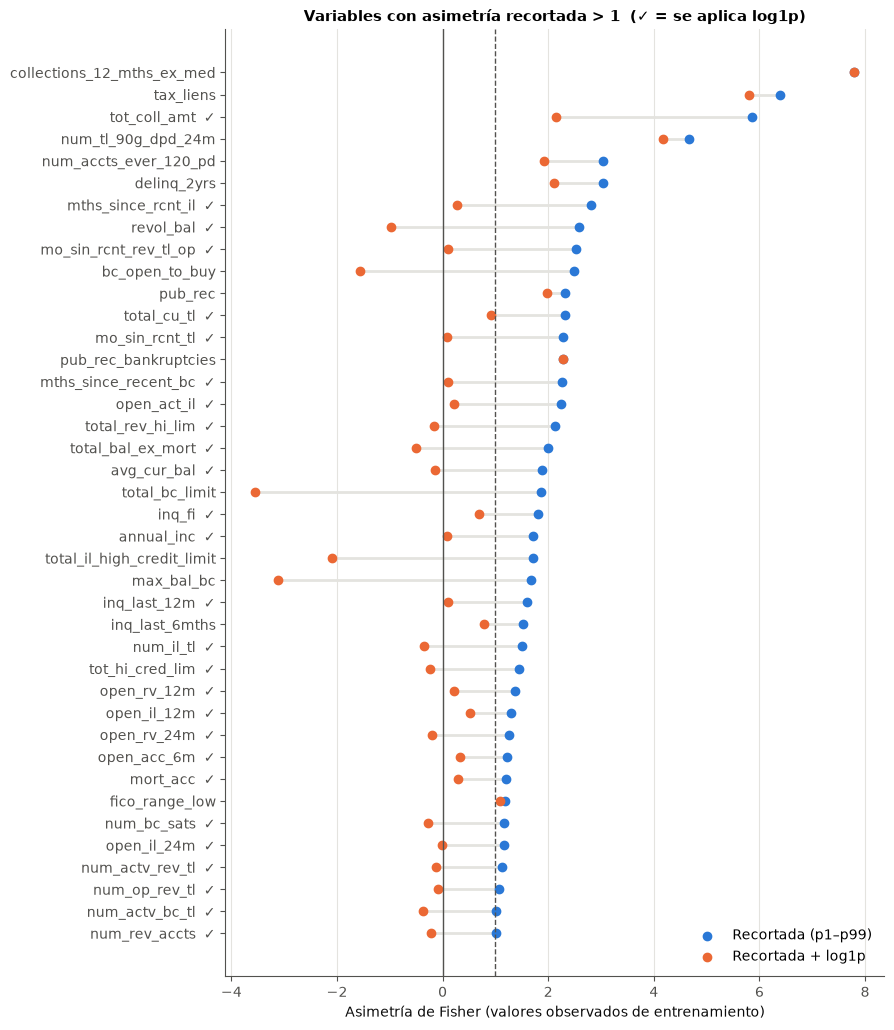

In [10]:
asimetricas = resumen.loc[originales].query('asim_recortada > 1').sort_values('asim_recortada')
log_si = tratamientos.loc[asimetricas.index, 'log1p']
fig, ax = plt.subplots(figsize=(8.5, 0.27 * len(asimetricas) + 1.5))
posiciones = np.arange(len(asimetricas))
for y_pos, (col, fila) in zip(posiciones, asimetricas.iterrows()):
    ax.plot([fila['asim_recortada'], fila['asim_log_recortada']], [y_pos, y_pos], color=REJILLA, linewidth=2, zorder=1)
ax.scatter(asimetricas['asim_recortada'], posiciones, color=AZUL, s=36, zorder=2, label='Recortada (p1–p99)')
ax.scatter(asimetricas['asim_log_recortada'], posiciones, color=NARANJA, s=36, zorder=2, label='Recortada + log1p')
ax.set_yticks(posiciones, [f'{c}  ✓' if log_si[c] else c for c in asimetricas.index])
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.axvline(1, color=TINTA_2, linewidth=1, linestyle='--')
ax.set_xlabel('Asimetría de Fisher (valores observados de entrenamiento)')
ax.set_title('Variables con asimetría recortada > 1  (✓ = se aplica log1p)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
guardar(fig, 'outliers_asimetria.png')
plt.show()

## 4. Antes y después en variables clave

Se ajusta `PreprocesadorNumerico` sin escalado, para ver solo el efecto de la winsorización y de `log1p` sobre la distribución observada.

Además se comprueba que los transformadores **respetan los NaN**: aplicado a `X_obs`, donde los imputados vuelven a ser NaN, el pipeline los deja en las mismas posiciones sin imputar.

Los NaN quedan en las mismas posiciones: winsorización y log1p no imputan.


Figura guardada en reports/figures/outliers_antes_despues.png


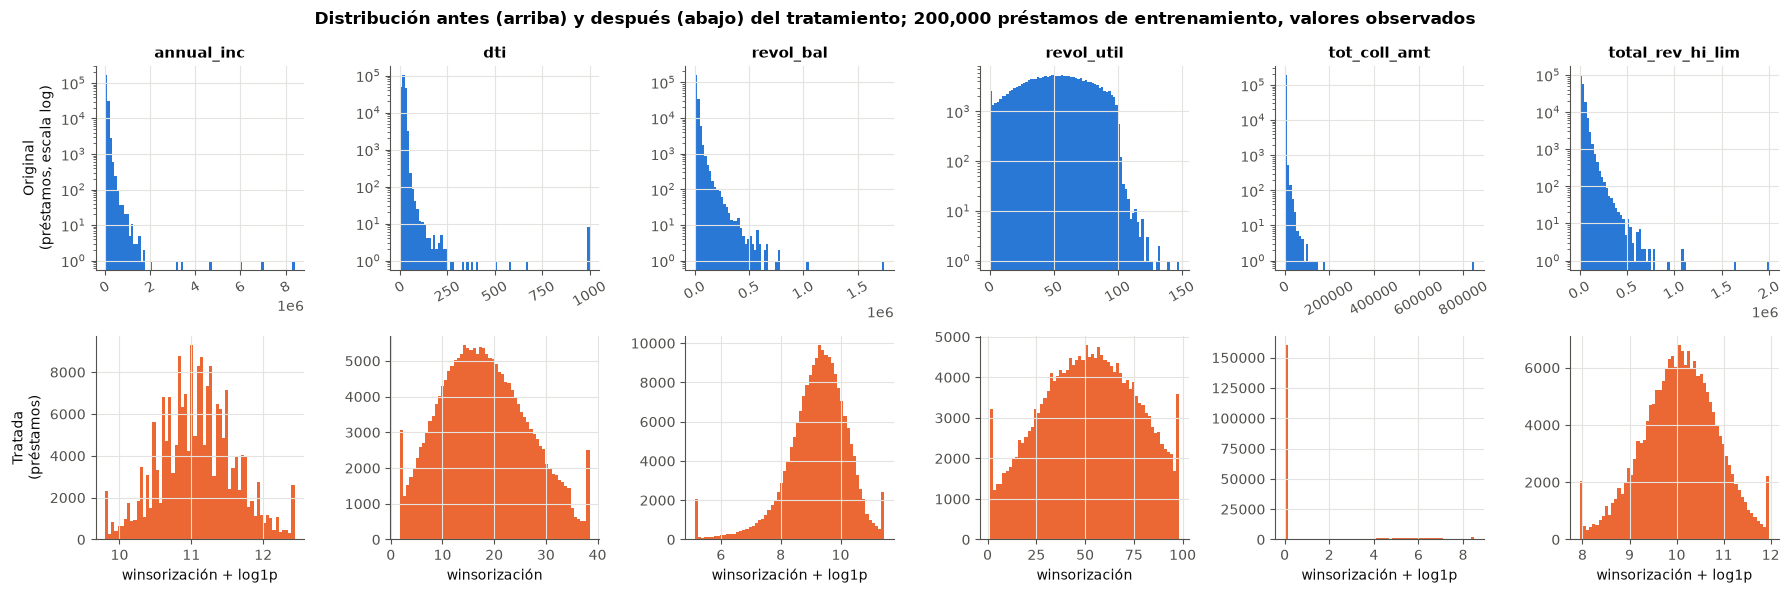

In [11]:
solo_forma = PreprocesadorNumerico(escalador=None).fit(X_ent)
X_obs_forma = solo_forma.transform(X_obs)
assert X_obs_forma.isna().equals(X_obs.isna()), 'Los NaN deben pasar sin cambios'
print('Los NaN quedan en las mismas posiciones: winsorización y log1p no imputan.')

CLAVE = ['annual_inc', 'dti', 'revol_bal', 'revol_util', 'tot_coll_amt', 'total_rev_hi_lim']
muestra = X_ent.sample(200_000, random_state=SEED).index
fig, ejes = plt.subplots(2, len(CLAVE), figsize=(18, 6))
for j, col in enumerate(CLAVE):
    original = X_obs.loc[muestra, col].dropna()
    tratada = X_obs_forma.loc[muestra, col].dropna()
    ejes[0, j].hist(original, bins=80, color=AZUL)
    ejes[0, j].set_yscale('log')
    ejes[0, j].set_title(col)
    ejes[1, j].hist(tratada, bins=60, color=NARANJA)
    ejes[1, j].set_xlabel(tratamientos.loc[col, 'tratamiento'])
    ejes[0, j].tick_params(axis='x', labelrotation=30)
ejes[0, 0].set_ylabel('Original\n(préstamos, escala log)')
ejes[1, 0].set_ylabel('Tratada\n(préstamos)')
fig.suptitle('Distribución antes (arriba) y después (abajo) del tratamiento; 200,000 préstamos de entrenamiento, valores observados', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_antes_despues.png')
plt.show()

Figura guardada en reports/figures/outliers_boxplots.png


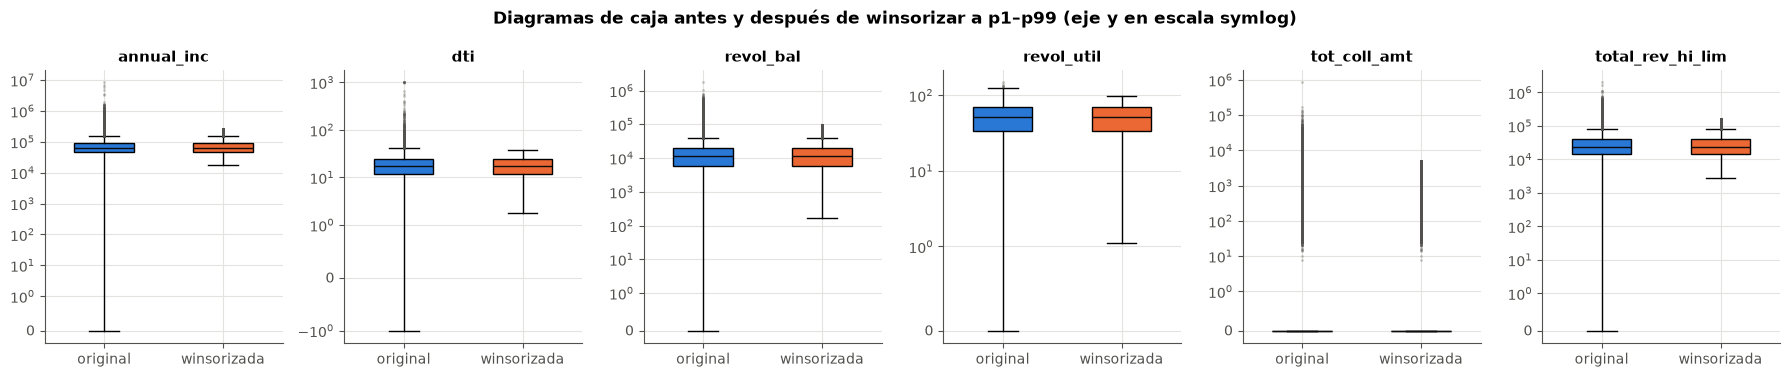

,inferior,superior,pct_recortado_ent
annual_inc,18000.00,252000.00,1.93
dti,1.76,38.45,1.99
revol_bal,167.56,95671.44,2.00
revol_util,1.10,98.30,1.95
tot_coll_amt,0.00,4923.00,0.95
total_rev_hi_lim,2800.00,157700.00,1.86


In [12]:
fig, ejes = plt.subplots(1, len(CLAVE), figsize=(18, 3.8))
winsor = solo_forma.pipeline_.named_steps['winsorizacion']
for ax, col in zip(ejes, CLAVE):
    original = X_obs.loc[muestra, col].dropna()
    recortada = original.clip(*winsor.limites_.loc[col])
    caja = ax.boxplot([original, recortada], tick_labels=['original', 'winsorizada'], widths=0.5,
                      patch_artist=True, flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.3, 'markeredgecolor': TINTA_2},
                      medianprops={'color': TINTA})
    for parche, color in zip(caja['boxes'], [AZUL, NARANJA]):
        parche.set_facecolor(color)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_title(col)
fig.suptitle('Diagramas de caja antes y después de winsorizar a p1–p99 (eje y en escala symlog)', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_boxplots.png')
plt.show()

winsor.limites_.loc[CLAVE].assign(
    pct_recortado_ent=[((X_obs[c] < winsor.limites_.loc[c, 'inferior']) | (X_obs[c] > winsor.limites_.loc[c, 'superior'])).mean() * 100 for c in CLAVE],
).round(2)

## 5. Comparación en validación

Se entrena la misma regresión logística del baseline (`max_iter=1000`, `random_state=42`) con 8 preprocesamientos: 4 tratamientos × 2 escaladores. Todos parten de los datos imputados por el Issue 5, sin imputación adicional. Se usan dos conjuntos de variables:

- **Baseline (9 variables):** permite comparar con la referencia del Issue 2 (validación: ROC-AUC 0.6336, PR-AUC 0.2855). Estas 9 columnas tienen menos de 1,000 nulos, que el Issue 5 imputa con la mediana como hacía el baseline, así que la fila "sin tratar + standard" debe reproducir la referencia.
- **Todas las numéricas de la cadena:** variables originales más indicadores del Issue 5. Es el conjunto que recibirá el PCA.

Cada configuración usa `PreprocesadorNumerico` y aprende sus reglas y percentiles solo con entrenamiento.

In [13]:
BASELINE = ['annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal',
            'total_acc', 'fico_range_low', 'delinq_2yrs', 'inq_last_6mths']
CONJUNTOS = {'Baseline (9)': BASELINE, f'Numéricas de la cadena ({X_ent.shape[1]})': list(X_ent.columns)}
TRATAMIENTOS = {
    'sin tratar': (False, False),
    'log1p': (True, False),
    'winsorización': (False, True),
    'winsorización + log1p': (True, True),
}

def evaluar(columnas, usar_log, usar_winsor, escalador):
    preprocesador = PreprocesadorNumerico(escalador=escalador, aplicar_log=usar_log, aplicar_winsor=usar_winsor)
    modelo = Pipeline([('pre', preprocesador), ('modelo', LogisticRegression(max_iter=1000, random_state=SEED))])
    inicio = time.time()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X_ent[columnas], y_ent)
    prob = modelo.predict_proba(X_val_num[columnas])[:, 1]
    return {
        'ROC-AUC': roc_auc_score(y_val, prob),
        'PR-AUC': average_precision_score(y_val, prob),
        'iteraciones': int(modelo.named_steps['modelo'].n_iter_[0]),
        'convergió': not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
        'segundos': round(time.time() - inicio, 1),
    }

filas = []
for conjunto, columnas in CONJUNTOS.items():
    for tratamiento, (usar_log, usar_winsor) in TRATAMIENTOS.items():
        for escalador in ('standard', 'robust'):
            filas.append({'conjunto': conjunto, 'tratamiento': tratamiento, 'escalador': escalador,
                          **evaluar(columnas, usar_log, usar_winsor, escalador)})
comparacion = pd.DataFrame(filas).set_index(['conjunto', 'tratamiento', 'escalador'])
comparacion.round(4)

ROC-AUC  PR-AUC  iteraciones  convergió  segundos
conjunto                     tratamiento           escalador                                                   
Baseline (9)                 sin tratar            standard    0.6336  0.2855            9       True       1.5
                                                   robust      0.6336  0.2855           12       True       1.5
                             log1p                 standard    0.6342  0.2845            9       True       1.4
                                                   robust      0.6343  0.2846           10       True       1.7
                             winsorización         standard    0.6356  0.2887            9       True       1.7
                                                   robust      0.6356  0.2888           11       True       2.1
                             winsorización + log1p standard    0.6362  0.2881           10       True       1.9
                                                   robust      0.6362  0.2881           10       True       1.9
Numéricas de la cadena (109) sin tratar            standard    0.6832  0.3386           47       True      15.5
                                                   robust      0.6501  0.3101         1000      False     181.5
                             log1p                 standard    0.6858  0.3401           47       True      18.3
                                                   robust      0.6784  0.3326         1000      False     186.0
                             winsorización         standard    0.6858  0.3444           46       True      17.6
                                                   robust      0.6578  0.3199         1000      False     185.4
                             winsorización + log1p standard    0.6883  0.3468           50       True      19.8
                                                   robust      0.6770  0.3360         1000      False     198.3

Figura guardada en reports/figures/outliers_comparacion_validacion.png


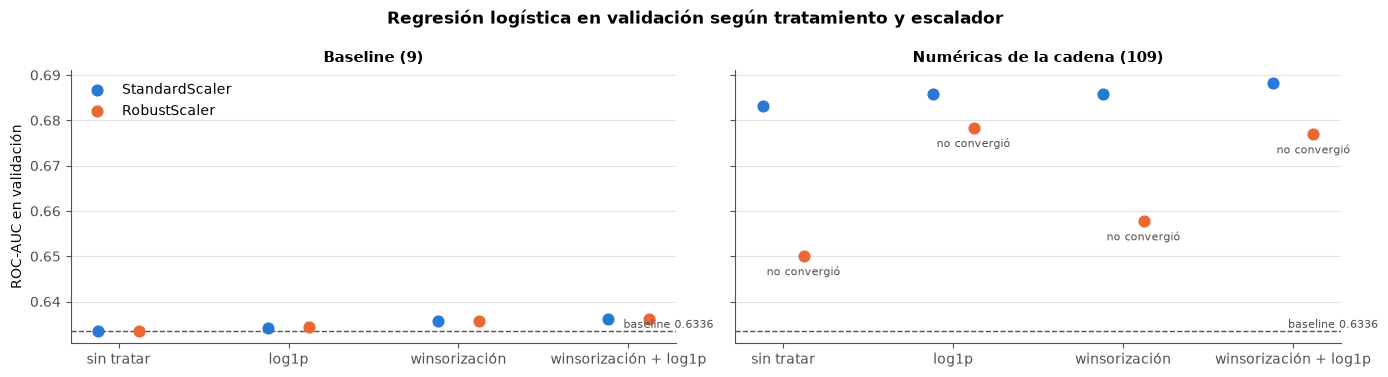

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
orden = list(TRATAMIENTOS)
for ax, conjunto in zip(ejes, CONJUNTOS):
    datos = comparacion.loc[conjunto]
    for desplazamiento, escalador, color in ((-0.12, 'standard', AZUL), (0.12, 'robust', NARANJA)):
        valores = datos.xs(escalador, level='escalador').loc[orden]
        posiciones = np.arange(len(orden)) + desplazamiento
        ax.scatter(posiciones, valores['ROC-AUC'], color=color, s=60, zorder=3,
                   label=f'{escalador.capitalize()}Scaler')
        for x, (_, fila) in zip(posiciones, valores.iterrows()):
            if not fila['convergió']:
                ax.annotate('no convergió', (x, fila['ROC-AUC']), textcoords='offset points', xytext=(0, -14),
                            ha='center', fontsize=8, color=TINTA_2)
    ax.axhline(0.6336, color=TINTA_2, linestyle='--', linewidth=1)
    ax.text(len(orden) - 0.5, 0.6336, 'baseline 0.6336', ha='right', va='bottom', fontsize=8, color=TINTA_2)
    ax.set_xticks(range(len(orden)), orden)
    ax.set_title(conjunto)
    ax.grid(axis='x', visible=False)
ejes[0].set_ylabel('ROC-AUC en validación')
ejes[0].legend(loc='upper left', frameon=False)
fig.suptitle('Regresión logística en validación según tratamiento y escalador', fontweight='bold')
fig.tight_layout()
guardar(fig, 'outliers_comparacion_validacion.png')
plt.show()

### `RobustScaler` frente a `StandardScaler`

`RobustScaler` resta la mediana y divide por el rango intercuartílico (IQR). Si el IQR es 0, scikit-learn usa escala 1, es decir, deja la columna en sus unidades originales. Con los datos de la cadena ocurre en muchas columnas, por tres motivos:

- **Conteos con más del 75 % de ceros:** Q1 = Q3 = 0.
- **Columnas que el Issue 5 imputó en más del 50 %:** la mediana imputada ocupa más de la mitad de los valores, así que Q1 = Q3.
- **Indicadores `_nulo` con menos del 25 % de unos:** Q1 = Q3 = 0.

Si esas columnas quedan en unidades mucho mayores que las demás, el problema queda mal condicionado y L-BFGS puede agotar sus iteraciones.

In [15]:
pre_robust = PreprocesadorNumerico(escalador='robust').fit(X_ent)
escala = pd.Series(pre_robust.pipeline_.named_steps['escalado'].scale_, index=X_ent.columns)
iqr_cero = escala.index[escala == 1.0]
desviaciones = pre_robust.transform(X_ent).std()
print(f'Columnas con IQR = 0 (RobustScaler no las escala): {len(iqr_cero)} de {X_ent.shape[1]} '
      f'({sum(c in indicadores for c in iqr_cero)} indicadores, {sum(c not in indicadores for c in iqr_cero)} variables originales)')
print(f'Desviación estándar tras RobustScaler: mínima {desviaciones.min():.3f}, máxima {desviaciones.max():,.1f} ({desviaciones.idxmax()})')
desviaciones.sort_values(ascending=False).head(6).round(2).to_frame('desviación tras RobustScaler')

Columnas con IQR = 0 (RobustScaler no las escala): 75 de 109 (48 indicadores, 27 variables originales)
Desviación estándar tras RobustScaler: mínima 0.124, máxima 3,086.2 (max_bal_bc)


,desviación tras RobustScaler
max_bal_bc,3086.20
mths_since_last_delinq,15.44
il_util,13.25
all_util,13.02
mths_since_recent_revol_delinq,12.89
mths_since_last_record,11.01


En 75 de las 109 columnas el IQR es 0: los 48 indicadores y 27 variables originales. `RobustScaler` las deja sin escalar; por ejemplo, `max_bal_bc` (60.1 % imputado por el Issue 5) queda con desviación 3,086, y los `mths_since_*` con desviaciones de 11 a 15. Con las 109 variables, L-BFGS agota las 1000 iteraciones en las cuatro configuraciones con `RobustScaler`, y el ROC-AUC queda entre 0.007 y 0.033 por debajo de su par con `StandardScaler`. Con las 9 variables del baseline, que casi no tienen nulos, ambos escaladores dan lo mismo.

Este hallazgo decide el escalado:

- **`RobustScaler` no sirve para este conjunto.** Su ventaja, la robustez frente a extremos, ya la aporta la winsorización. Su desventaja, no escalar columnas con IQR = 0, empeora el modelo con las variables de la cadena.
- **El PCA del Issue 7 necesita `StandardScaler`.** El PCA maximiza la varianza, así que todas las columnas deben entrar con varianza 1. Con `RobustScaler`, `max_bal_bc` dominaría los primeros componentes solo por su escala.

## 6. Pipeline final

**Tratamiento elegido: winsorización a p1–p99 + `log1p` en las variables asimétricas + `StandardScaler`, sobre los datos imputados por el Issue 5.** Es la configuración por defecto de `PreprocesadorNumerico`: aprende reglas y percentiles con los valores observados y no añade otra imputación.

In [16]:
preprocesador = PreprocesadorNumerico().fit(X_ent)   # fit solo con entrenamiento
Z_ent = preprocesador.transform(X_ent)
Z_val = preprocesador.transform(X_val_num)
print('Pasos:', [nombre for nombre, _ in preprocesador.pipeline_.steps])
print(f'Columnas con log1p: {len(preprocesador.columnas_log_)}; con winsorización: {len(preprocesador.columnas_winsor_)}; '
      f'solo escaladas (binarias): {len(preprocesador.columnas_) - len(preprocesador.columnas_winsor_)}')
print(f'NaN tras el pipeline -> entrenamiento: {Z_ent.isna().sum().sum()}, validación: {Z_val.isna().sum().sum()}')
print(f'Entrenamiento: medias en [{Z_ent.mean().min():.1e}, {Z_ent.mean().max():.1e}], desviaciones en [{Z_ent.std().min():.4f}, {Z_ent.std().max():.4f}]')
print(f'Validación (sin reajustar): medias en [{Z_val.mean().min():.3f}, {Z_val.mean().max():.3f}], desviaciones en [{Z_val.std().min():.3f}, {Z_val.std().max():.3f}]')

Pasos: ['winsorizacion', 'log1p', 'escalado']
Columnas con log1p: 27; con winsorización: 61; solo escaladas (binarias): 48
NaN tras el pipeline -> entrenamiento: 0, validación: 0


Entrenamiento: medias en [-9.8e-16, 1.6e-15], desviaciones en [1.0000, 1.0000]


Validación (sin reajustar): medias en [-0.006, 0.004], desviaciones en [0.990, 1.004]


Las medias y desviaciones de validación quedan cerca de 0 y 1 sin reajustar el pipeline: los percentiles y las escalas de entrenamiento se aplican tal cual.

## 7. Conclusiones

**Tratamiento definido para las 109 columnas numéricas de la cadena** (61 variables originales y 48 indicadores del Issue 5). Las reglas y los percentiles se aprenden solo con los valores observados de entrenamiento:

| Tratamiento | Columnas | Criterio |
|---|---|---|
| Winsorización p1–p99 + `log1p` | 27: `annual_inc`, `revol_bal`, `total_rev_hi_lim`, `tot_hi_cred_lim`, `tot_coll_amt`, `avg_cur_bal`, `total_bal_ex_mort`, `mths_since_rcnt_il`, `mths_since_recent_bc`, los conteos de cuentas abiertas y consultas, entre otras | Sin negativos; asimetría recortada > 1; el logaritmo la reduce al menos a la mitad |
| Solo winsorización p1–p99 | 34: `loan_amnt`, `dti`, `revol_util`, `fico_range_low`, `pub_rec`, `delinq_2yrs`, `max_bal_bc`, `bc_open_to_buy`, `mths_since_*`, entre otras | Distribución casi simétrica, negativos (`dti`), o el logaritmo no mejora o invierte la asimetría |
| Sin transformación (binarias) | 48 indicadores `<columna>_nulo` del Issue 5 | Son 0/1: no tienen extremos |
| Escalado | las 109 | `StandardScaler` |

Integración con el Issue 5:

- **No se añade otra imputación:** el pipeline transforma los datos tal como los imputó el Issue 5 (mediana o moda, más indicadores).
- **Las estadísticas se calculan sin los valores imputados.** En las columnas del bloque de 2016 (60 % imputado), la mediana repetida anulaba el IQR y desplazaba los percentiles; por ejemplo, el p99 de `max_bal_bc` pasaba de 24,374 a 19,404. Usar los valores observados cambia la decisión de `log1p` en 5 columnas: `open_il_12m`, `total_cu_tl`, `mths_since_recent_inq`, `num_bc_tl` y `num_tl_op_past_12m`.
- **De los 48 indicadores del Issue 5, solo 24 son distintos:** hay 5 grupos de copias exactas, el mayor con 13 columnas. No afectan a la regresión logística, pero conviene dejar uno por grupo antes del PCA.

Resultados en validación (ROC-AUC / PR-AUC):

- **El tratamiento mejora al modelo sin tratar:**
  - Con las 109 numéricas de la cadena: de 0.6832 / 0.3386 a **0.6883 / 0.3468**.
  - Con las 9 variables del baseline: de 0.6336 / 0.2855 (referencia reproducida) a 0.6362 / 0.2881.
  - La winsorización aporta la mayor parte de la mejora en PR-AUC, y `log1p` la complementa en ROC-AUC.
- **El aumento frente al baseline** (0.6336 → 0.6832 sin tratar) viene de usar todas las numéricas de la cadena, incluidos los indicadores de nulo del Issue 5 y `loan_amnt`, no de este issue.
- **`StandardScaler` es el escalado final.** `RobustScaler` no converge con las 109 variables, porque 75 columnas tienen IQR = 0.
- **No se eliminan filas.** Los centinelas e imposibles (`dti = 999`, `annual_inc = 0`, límites de 9,999,999) se recortan a percentiles de entrenamiento: entre 1 % y 2 % de recorte por variable.

La sección 8 aplica `preprocesador` a `X_train`, `X_val` y `X_test` para el Issue 7. Para usarlo fuera de la cadena:

```python
from src.features import PreprocesadorNumerico
preprocesador = PreprocesadorNumerico().fit(X_train)   # salida del Issue 5
Z_val = preprocesador.transform(X_val)
```

## 8. Salida para el Issue 7

Se aplica `preprocesador` (ajustado con entrenamiento en la sección 6) a las columnas numéricas de `X_train`, `X_val` y `X_test`. Las categóricas se conservan sin cambios y en el mismo orden.

In [17]:
numericas_cadena = preprocesador.columnas_
for nombre in ['X_train', 'X_val', 'X_test']:
    X = globals()[nombre].copy()
    X[numericas_cadena] = preprocesador.transform(X)
    globals()[nombre] = X

print(f'Numéricas tratadas: {len(numericas_cadena)}; categóricas sin cambios: {X_train.shape[1] - len(numericas_cadena)}')
print(f'X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')
print(f'NaN en numéricas -> X_train: {X_train[numericas_cadena].isna().sum().sum()}, X_val: {X_val[numericas_cadena].isna().sum().sum()}, X_test: {X_test[numericas_cadena].isna().sum().sum()}')

Numéricas tratadas: 109; categóricas sin cambios: 8
X_train: (862757, 117) | X_val: (215690, 117) | X_test: (269612, 117)
NaN en numéricas -> X_train: 0, X_val: 0, X_test: 0


## Checkpoint

Se guardan las particiones en `data/checkpoints/issue6/` para que `issue7.ipynb` las cargue sin volver a ejecutar la cadena.

In [18]:
from src.checkpoints import guardar_checkpoint

guardar_checkpoint('issue6', X_train=X_train, X_val=X_val, X_test=X_test,
                   y_train=y_train, y_val=y_val, y_test=y_test)

Checkpoint issue6: X_train (862757, 117) guardado


Checkpoint issue6: X_val (215690, 117) guardado


Checkpoint issue6: X_test (269612, 117) guardado
Checkpoint issue6: y_train (862757, 1) guardado


Checkpoint issue6: y_val (215690, 1) guardado
Checkpoint issue6: y_test (269612, 1) guardado
Checkpoint guardado en /home/daros/academico/2026-02/MachineLearning/Proyecto/data/checkpoints/issue6
